# HNODE: Shear Flow

This notebook trains a conditional HNODE on 2D shear flow simulations at multiple Reynolds and Schmidt numbers.
The state is a 64-dimensional latent vector produced by a **learned Swin-V2 autoencoder** trained end-to-end
with the dynamics model. The model is conditioned on `z = (log10(Re), log10(Sc))`.

**Data**: Shear flow simulation snapshots (256×512, 4 channels) stored as per-frame `.npy` files. Full datasets available from The Well https://polymathic-ai.org/the_well/. We include a sample trajectory from the training and test sets in this directory.

**Checkpoint**: Set `CHECKPOINT_PATH` to a `.pt` file to resume from a saved checkpoint,
or set it to `None` to train from scratch.

In [14]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
import random
from torch.utils.data import DataLoader, Dataset
from einops import rearrange

from hybrid_node_solver import HybridNODESolver
from neural_networks import CrossAttnTransformer
from swin_transformer_v2 import SwinEncoder, SwinDecoder
from soap import SOAP

torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## Configuration

In [15]:
# Paths to training and test frame directories.
# Expected structure: parent_dir/traj_N/frame_M.npy + parent_dir/stats.npy
TRAIN_DATA_PATH = "./shear_flow_frames_train"
TEST_DATA_PATH = "./shear_flow_frames_test"

# Path to a saved checkpoint to resume training, or None to train from scratch.
CHECKPOINT_PATH = "./shear_flow_redo_part_2.pt"
SAVE_PATH = "shear_flow_checkpoint.pt"
SAVE_EVERY = 200

## Dataset

In [16]:
class SubsamplingDataset(Dataset):
    """
    Expected directory structure::

        parent_directory/
            traj_0/
                scalars.npy          # scalar parameters for this trajectory (Re, Sc)
                frame_0.npy
                frame_1.npy
                ...
            traj_1/
                ...
            stats.npy                # dataset mean and std per channel
    """

    def __init__(
        self,
        parent_directory,
        n_trajectories,
        n_frames_per_trajectory=200,
        bdf_degree=2,
        N=4,
        seed=None,
    ):
        self.parent_directory = parent_directory
        self.n_trajectories = n_trajectories
        self.n_frames_per_trajectory = n_frames_per_trajectory
        self.bdf_degree = bdf_degree
        self.seed = seed
        self.N = N

        if not os.path.exists(parent_directory):
            raise FileNotFoundError(f"Data directory not found: {parent_directory}")

    def __len__(self):
        return self.n_trajectories

    def __getitem__(self, idx):
        if self.seed is not None:
            random.seed(self.seed + idx)

        traj_dir = os.path.join(self.parent_directory, f"traj_{idx}")
        scalars = torch.from_numpy(np.load(os.path.join(traj_dir, "scalars.npy")))

        start_index = 1
        start_indices = list(range(start_index - self.bdf_degree + 1, start_index + 1))
        indices_to_decode = list(range(start_index, self.n_frames_per_trajectory))
        random.shuffle(indices_to_decode)
        indices_to_decode = indices_to_decode[: self.N]

        start_frames = torch.stack(
            [
                torch.from_numpy(np.load(os.path.join(traj_dir, f"frame_{i}.npy")))
                for i in start_indices
            ]
        )
        target_frames = torch.stack(
            [
                torch.from_numpy(np.load(os.path.join(traj_dir, f"frame_{i}.npy")))
                for i in indices_to_decode
            ]
        )
        indices_to_decode = torch.tensor(indices_to_decode) - start_index

        return {
            "start_frames": start_frames.double(),
            "target_frames": target_frames.double(),
            "scalars": scalars.double(),
            "indices_to_decode": indices_to_decode,
        }


latent_dim = 64
dt = 1e-2
num_time_steps_per_data_sample = 200
N = 40  # number of training rollouts
batch_size = 8

delta_t = dt * num_time_steps_per_data_sample / N
N_t = (
    num_time_steps_per_data_sample // N
) + 1  # collocation points per rollout (M = N_t - 1)

train_dataset = SubsamplingDataset(
    TRAIN_DATA_PATH, n_trajectories=896, n_frames_per_trajectory=200, bdf_degree=2, N=12
)
test_dataset = SubsamplingDataset(
    TEST_DATA_PATH, n_trajectories=112, n_frames_per_trajectory=200, bdf_degree=2, N=12
)

train_dataloader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True,
)
test_dataloader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=4,
    pin_memory=True,
    persistent_workers=True,
    drop_last=True,
)

_stats = np.load(os.path.join(TRAIN_DATA_PATH, "stats.npy"), allow_pickle=True).item()
frame_mean = torch.tensor(_stats["mean"], dtype=torch.float64).to(device)
frame_std = torch.tensor(_stats["std"], dtype=torch.float64).to(device)

# Conditioning: log10(Re) and log10(Sc), normalised by training-set statistics
reynolds = torch.tensor([1e4, 5e4, 1e5, 5e5]).log10()
schmidt = torch.tensor([0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0]).log10()
z_mean = torch.tensor([reynolds.mean(), schmidt.mean()]).unsqueeze(0).to(device)
z_std = torch.tensor([reynolds.std(), schmidt.std()]).unsqueeze(0).to(device)

print(
    f"Train trajectories: {len(train_dataset)}, Test trajectories: {len(test_dataset)}"
)
print(f"delta_t={delta_t:.4f}, N_t={N_t} (M={N_t-1} intervals per rollout)")

Train trajectories: 896, Test trajectories: 112
delta_t=0.0500, N_t=6 (M=5 intervals per rollout)


## Model

In [17]:
encoder = SwinEncoder(
    img_size=(256, 512),
    patch_size=4,
    in_chans=4,
    latent_dim=latent_dim,
    embed_dim=96,
    depths=(2, 2, 6, 2),
    num_heads=(3, 6, 12, 24),
    window_size=(8, 8),
    mlp_ratio=4,
    drop=0.0,
    attn_drop=0.0,
    drop_path_rate=0.0,
    final_channels=64,
).to(device)

decoder = SwinDecoder(
    img_size=(256, 512),
    patch_size=4,
    out_chans=4,
    latent_dim=latent_dim,
    embed_dim=96,
    depths=(2, 2, 6, 2),
    num_heads=(3, 6, 12, 24),
    window_size=(8, 8),
    mlp_ratio=4,
    drop=0.0,
    attn_drop=0.0,
    drop_path_rate=0.0,
).to(device)

encoder = torch.compile(encoder)
decoder = torch.compile(decoder)

nn_rhs_model = CrossAttnTransformer(
    problem_dim=latent_dim,
    latent_dim=64 * 4,
    num_blocks=3,
    num_heads=4,
    z_dim=2,
    dropout_rate=0,
    activation=torch.nn.Tanh(),
    use_self_attention_z_block=True,
).to(device)

solver = HybridNODESolver(
    nn_rhs_model,
    delta_t,
    N_t,
    latent_dim,
    N,
    backprop_type="matrix_free",
    use_manual_jacobian=True,
    use_sparse_solver=False,
    use_cpu_solver=False,
    verbose=False,
    device=device,
)

n_params = sum(
    p.numel()
    for p in list(encoder.parameters())
    + list(decoder.parameters())
    + list(nn_rhs_model.parameters())
)
print(f"Total parameters: {n_params:,}")

Total parameters: 69,032,704


## Optimizer and Checkpoint

In [18]:
def get_param_groups(models, weight_decay=1e-4):
    """Separate transformer params into decay / no-decay groups (standard practice)."""
    if not isinstance(models, (list, tuple)):
        models = [models]
    decay, no_decay = [], []
    for model in models:
        for name, param in model.named_parameters():
            if not param.requires_grad:
                continue
            if (
                param.ndim <= 1
                or "bias" in name
                or "norm" in name.lower()
                or "ln" in name
            ):
                no_decay.append(param)
            else:
                decay.append(param)
    return [
        {"params": decay, "weight_decay": weight_decay},
        {"params": no_decay, "weight_decay": 0.0},
    ]


optimizer = SOAP(
    get_param_groups([nn_rhs_model, encoder, decoder]),
    precondition_frequency=10,
    lr=1e-4,
)

train_loss_history, test_loss_history = [], []

if CHECKPOINT_PATH is not None:
    if os.path.exists(CHECKPOINT_PATH):
        checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
        encoder.load_state_dict(checkpoint["encoder"])
        decoder.load_state_dict(checkpoint["decoder"])
        nn_rhs_model.load_state_dict(checkpoint["nn_rhs_model"])
        optimizer.load_state_dict(checkpoint["optimizer"])
        train_loss_history = checkpoint["train_loss_history"]
        test_loss_history = checkpoint["test_loss_history"]
        print(
            f"Loaded checkpoint from {CHECKPOINT_PATH} ({len(train_loss_history)} steps)"
        )
    else:
        print(f"Checkpoint not found at {CHECKPOINT_PATH}, training from scratch.")

Loaded checkpoint from ./shear_flow_redo_part_2.pt (144001 steps)


## Training

In [19]:
def normalize(frames):
    return (frames - frame_mean) / frame_std


def vrmse_loss(pred, target, eps=1e-3):
    """Variance-normalised RMSE^2 over batch, time, and channel. pred/target: (B, T, H, W, C)."""
    spatial_dims = (-3, -2)
    mse = (pred - target).pow(2).mean(dim=spatial_dims)
    var = target.var(dim=spatial_dims)
    return (mse / (var + eps)).mean()


def compute_loss(batch):
    B = batch["start_frames"].shape[0]
    start_frames = normalize(batch["start_frames"].to(device))
    start_latents = rearrange(
        encoder(rearrange(start_frames, "B T H W C -> (B T) C H W")),
        "(B T) L -> B T L",
        B=B,
    )
    latent_batch = {
        "J_init": (start_latents[:, 1, :] - start_latents[:, 0, :]) / dt,
        "u_init": (start_latents[:, 0, :] + start_latents[:, 1, :]) / 2.0,
        "z": (batch["scalars"].to(device).log10() - z_mean) / z_std,
    }
    _, u_hat_rollout = solver.evolve_batch(latent_batch)
    latents_to_decode = rearrange(
        torch.vmap(lambda array, indices: array[indices])(
            u_hat_rollout, batch["indices_to_decode"]
        ),
        "B T L -> (B T) L",
    )
    reconstructed = rearrange(
        decoder(latents_to_decode), "(B T) C H W -> B T H W C", B=B
    )
    return vrmse_loss(reconstructed, normalize(batch["target_frames"].to(device)))


def save_checkpoint():
    torch.save(
        {
            "encoder": encoder.state_dict(),
            "decoder": decoder.state_dict(),
            "nn_rhs_model": nn_rhs_model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "train_loss_history": train_loss_history,
            "test_loss_history": test_loss_history,
        },
        SAVE_PATH,
    )


solver.verbose = False
test_iter = iter(test_dataloader)
NUM_EPOCHS = 0

for epoch in range(NUM_EPOCHS):
    for batch_ndx, batch in enumerate(train_dataloader):
        optimizer.zero_grad()
        loss = compute_loss(batch)
        loss.backward()
        optimizer.step()

        iteration = len(train_loss_history)
        train_loss_history.append(loss.item())

        if iteration % 25 == 0:
            try:
                test_batch = next(test_iter)
            except StopIteration:
                test_iter = iter(test_dataloader)
                test_batch = next(test_iter)
            with torch.no_grad():
                test_loss = compute_loss(test_batch)
            test_loss_history.append(test_loss.item())
        else:
            test_loss_history.append(
                test_loss_history[-1] if test_loss_history else float("nan")
            )

        if iteration % SAVE_EVERY == 0:
            save_checkpoint()

        print(
            f"Epoch {epoch} | Batch {batch_ndx}/{len(train_dataloader)} "
            f"| Train {loss.item():.6e} | Test {test_loss_history[-1]:.6e}"
        )

## Evaluation

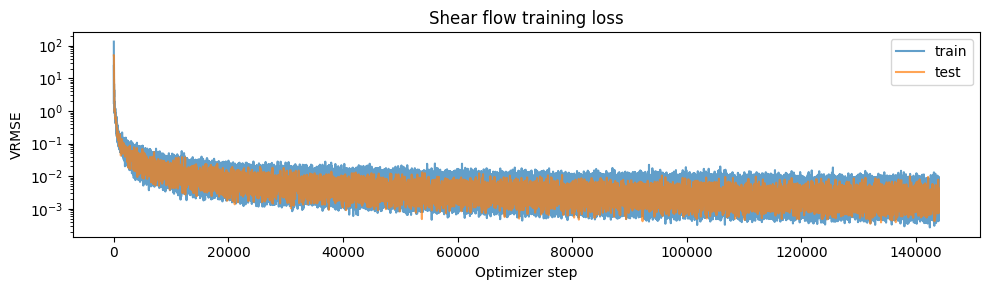

In [20]:
# Loss curves
fig, ax = plt.subplots(figsize=(10, 3))
ax.semilogy(train_loss_history, alpha=0.7, label="train")
ax.semilogy(test_loss_history, alpha=0.7, label="test")
ax.set_xlabel("Optimizer step")
ax.set_ylabel("VRMSE")
ax.set_title("Shear flow training loss")
ax.legend()
plt.tight_layout()
plt.show()

rebuilding indexers... 
done rebuilding indexers


/tmp/ipykernel_55320/2497605841.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


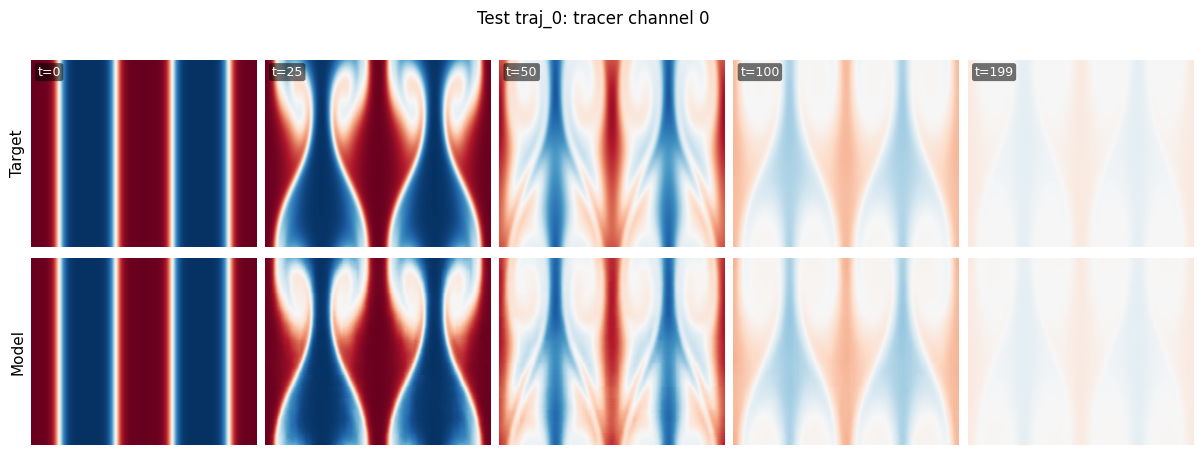

In [21]:
# Simple rollout on traj_0 of the test data: tracer channel target vs model
TRAJ_INDEX = 0
time_indices = [0, 25, 50, 100, 199]
tracer_channel = 0

encoder.eval()
decoder.eval()
nn_rhs_model.eval()

traj_dir = os.path.join(TEST_DATA_PATH, f"traj_{TRAJ_INDEX}")
with torch.no_grad():
    frames = torch.stack(
        [
            torch.from_numpy(np.load(os.path.join(traj_dir, f"frame_{t}.npy")))
            for t in range(num_time_steps_per_data_sample)
        ]
    ).double()
    scalars = torch.from_numpy(np.load(os.path.join(traj_dir, "scalars.npy"))).double()

    frames = frames.unsqueeze(0).to(device)  # (1, T, H, W, C)
    frames_norm = normalize(frames)

    start_frames = frames_norm[:, :2]
    start_latents = rearrange(
        encoder(rearrange(start_frames, "B T H W C -> (B T) C H W")),
        "(B T) L -> B T L",
        B=1,
    )
    latent_batch = {
        "J_init": (start_latents[:, 1, :] - start_latents[:, 0, :]) / dt,
        "u_init": (start_latents[:, 0, :] + start_latents[:, 1, :]) / 2.0,
        "z": (scalars.unsqueeze(0).to(device).log10() - z_mean) / z_std,
    }
    _, u_hat_rollout = solver.evolve_batch(latent_batch)

    latents_to_decode = rearrange(u_hat_rollout, "B T L -> (B T) L")
    recon_norm = rearrange(decoder(latents_to_decode), "(B T) C H W -> B T H W C", B=1)
    recon_norm = torch.cat([frames_norm[:, :1], recon_norm[:, :-1]], dim=1)

    target = frames[0].cpu()
    recon = (recon_norm * frame_std + frame_mean)[0].cpu()

tracer_all = torch.cat(
    [target[:, :, :, tracer_channel], recon[:, :, :, tracer_channel]], dim=0
)
vmin, vmax = tracer_all.min().item(), tracer_all.max().item()

fig, axes = plt.subplots(
    2,
    len(time_indices),
    figsize=(3.0 * len(time_indices), 5.0),
    gridspec_kw={"hspace": 0.06, "wspace": 0.04},
)
row_labels = ["Target", "Model"]
label_kw = dict(
    fontsize=9,
    color="white",
    bbox=dict(
        facecolor="black", alpha=0.55, edgecolor="none", boxstyle="round,pad=0.2"
    ),
)

for col, t_idx in enumerate(time_indices):
    for row, data in enumerate([target, recon]):
        ax = axes[row, col]
        ax.imshow(
            data[t_idx, :, :, tracer_channel].numpy(),
            cmap="RdBu_r",
            vmin=vmin,
            vmax=vmax,
            aspect="auto",
        )
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
        if row == 0:
            ax.text(
                0.03,
                0.97,
                f"t={t_idx}",
                transform=ax.transAxes,
                ha="left",
                va="top",
                **label_kw,
            )
        if col == 0:
            ax.set_ylabel(row_labels[row], fontsize=11)

fig.suptitle(f"Test traj_{TRAJ_INDEX}: tracer channel {tracer_channel}", y=0.98)
plt.tight_layout()
plt.show()